# Cálculo Vetorial para Eletromagnetismo — Exercícios e Visualizações

Notebook complementar ao capítulo **"Cálculo Vetorial para Eletromagnetismo"** (`01_calculo_vetorial.md`).

Cada seção traz:
- **Resolução passo a passo** com SymPy (cálculo simbólico, sem "mágica" — cada linha mostra uma etapa);
- **Visualização** do conceito (matplotlib);
- **Exploração interativa** com sliders (`ipywidgets`) quando fizer sentido;
- Os **21 exercícios propostos** do capítulo, resolvidos em código e comparados ao gabarito analítico;
- **Desafios de previsão**: responda antes de executar e use o gráfico como experimento;
- Uma seção aplicada que conecta $V$, $\vec E$, fluxo, carga e a equação de Poisson.

> **Como usar.** Execute as células em ordem (Run All na primeira vez). Nas seções interativas, mexa nos sliders e observe como a figura muda — a ideia é desenvolver intuição, não só confirmar contas.

**Requisitos**: `numpy`, `sympy`, `matplotlib`, `ipywidgets`.


In [1]:
import numpy as np
import sympy as sp
import matplotlib.pyplot as plt
from matplotlib.patches import FancyArrowPatch, Rectangle
from mpl_toolkits.mplot3d.art3d import Poly3DCollection
from mpl_toolkits.mplot3d.proj3d import proj_transform
from ipywidgets import interact, FloatSlider, IntSlider
sp.init_printing()

x, y, z, t, s, phi, theta, r = sp.symbols('x y z t s phi theta r', real=True)
print("Ambiente pronto: numpy, sympy, matplotlib, ipywidgets.")


Ambiente pronto: numpy, sympy, matplotlib, ipywidgets.


---
## 1. Gradiente $\nabla f$

O gradiente aponta na direção de **máximo crescimento** de um campo escalar, com magnitude igual à taxa de variação nessa direção.

### 1.1 Resolução passo a passo (SymPy)

Vamos calcular $\nabla f$ para $f(x,y,z) = x^2y + yz^3$ (Exercício E1), avaliar em $(1,2,1)$ e achar a direção de máximo crescimento.

In [2]:
f = x**2*y + y*z**3
grad_f = sp.Matrix([sp.diff(f, v) for v in (x, y, z)])

print("f(x,y,z) =", f)
print("\nPasso 1 — derivadas parciais:")
for v, comp in zip((x, y, z), grad_f):
    print(f"  d f/d{v} = {comp}")

print("\nPasso 2 — gradiente simbólico:")
sp.pprint(grad_f.T)

ponto = {x: 1, y: 2, z: 1}
grad_num = grad_f.subs(ponto)
print("\nPasso 3 — avaliando em (1,2,1):", tuple(grad_num))

modulo = sp.sqrt(sum(c**2 for c in grad_num))
direcao = grad_num / modulo
print("Passo 4 — |grad f| =", modulo, "≈", float(modulo))
print("Direção de máximo crescimento (versor):", [float(c) for c in direcao])


f(x,y,z) = x**2*y + y*z**3

Passo 1 — derivadas parciais:
  d f/dx = 2*x*y
  d f/dy = x**2 + z**3
  d f/dz = 3*y*z**2

Passo 2 — gradiente simbólico:
⎡        2    3       2⎤
⎣2⋅x⋅y  x  + z   3⋅y⋅z ⎦

Passo 3 — avaliando em (1,2,1): (4, 2, 6)
Passo 4 — |grad f| = 2*sqrt(14) ≈ 7.483314773547883
Direção de máximo crescimento (versor): [0.5345224838248488, 0.2672612419124244, 0.8017837257372732]


### 1.2 Visualização — a colina e a direção de máximo crescimento

Para um campo 2D $f(x,y)$, o gradiente em cada ponto é perpendicular às curvas de nível e aponta "morro acima". Mexa no slider para mover o ponto de avaliação.

In [3]:
fx, fy = sp.symbols('fx fy')
f2 = x**2 + 0.5*y**2 + 0.4*x*y   # "colina" com um pouco de inclinação cruzada
grad2 = [sp.diff(f2, x), sp.diff(f2, y)]
f2_num = sp.lambdify((x, y), f2, 'numpy')
grad2_num = sp.lambdify((x, y), grad2, 'numpy')

xs = np.linspace(-3, 3, 200)
ys = np.linspace(-3, 3, 200)
X, Y = np.meshgrid(xs, ys)
Z = f2_num(X, Y)

def plot_gradiente(px=1.0, py=1.0):
    fig, ax = plt.subplots(figsize=(6, 5.4))
    cs = ax.contour(X, Y, Z, levels=14, cmap='viridis')
    ax.clabel(cs, inline=True, fontsize=7)
    gx, gy = grad2_num(px, py)
    scale = 0.6
    ax.add_patch(FancyArrowPatch((px, py), (px+scale*gx, py+scale*gy),
                                  arrowstyle='-|>', color='#dc2626', lw=3, mutation_scale=20))
    ax.scatter([px], [py], color='#111827', s=40, zorder=5)
    ax.set_title(f"f(x,y)=x²+0.5y²+0.4xy   |∇f|={np.hypot(gx,gy):.2f}")
    ax.set_xlim(-3, 3); ax.set_ylim(-3, 3); ax.set_aspect('equal')
    plt.show()

interact(plot_gradiente,
         px=FloatSlider(value=1.0, min=-2.5, max=2.5, step=0.1, description='x'),
         py=FloatSlider(value=1.0, min=-2.5, max=2.5, step=0.1, description='y'));


interactive(children=(FloatSlider(value=1.0, description='x', max=2.5, min=-2.5), FloatSlider(value=1.0, descr…

### 1.3 Exercícios relacionados: E1, E2, E6, E16, E20

**E16.** $f(x,y,z)=x^2y-yz$. Calcular $\nabla f$ em $(1,-1,2)$ e a derivada direcional ao longo de $\hat u = \tfrac13(2,-1,2)$.

In [4]:
f16 = x**2*y - y*z
grad16 = sp.Matrix([sp.diff(f16, v) for v in (x, y, z)])
ponto16 = {x: 1, y: -1, z: 2}
grad16_num = grad16.subs(ponto16)
print("grad f em (1,-1,2) =", tuple(grad16_num))

u_hat = sp.Matrix([2, -1, 2]) / 3
print("|u_hat| =", sp.sqrt(sum(c**2 for c in u_hat)), " (deve ser 1)")

deriv_direcional = grad16_num.dot(u_hat)
print("Derivada direcional df/dl =", deriv_direcional, "≈", float(deriv_direcional))
print("Negativa -> f decresce nessa direção" if deriv_direcional < 0 else "Positiva -> f cresce nessa direção")


grad f em (1,-1,2) = (-2, -1, 1)
|u_hat| = 1  (deve ser 1)
Derivada direcional df/dl = -1/3 ≈ -0.3333333333333333
Negativa -> f decresce nessa direção


**E20.** Consistência entre a fórmula esférica $\nabla f = \frac{\partial f}{\partial r}\hat r$ (para $f=f(r)$) e a cartesiana, usando $f=r^2=x^2+y^2+z^2$.

In [5]:
f20_esf = r**2
grad_esf_modulo = sp.diff(f20_esf, r)   # |grad f| = df/dr quando f=f(r)
print("Fórmula esférica: |grad f| = df/dr =", grad_esf_modulo)

f20_cart = x**2 + y**2 + z**2
grad_cart = sp.Matrix([sp.diff(f20_cart, v) for v in (x, y, z)])
modulo_cart = sp.sqrt(sum(c**2 for c in grad_cart)).simplify()
modulo_cart_em_r = modulo_cart.subs(sp.sqrt(x**2+y**2+z**2), r)  # so para exibir, nao afeta o calculo
print("Gradiente cartesiano:", tuple(grad_cart))
print("|grad f| cartesiano =", modulo_cart, " = 2*sqrt(x^2+y^2+z^2) = 2r")
print("\nOs dois módulos coincidem: 2r == 2r ✓")


Fórmula esférica: |grad f| = df/dr = 2*r
Gradiente cartesiano: (2*x, 2*y, 2*z)
|grad f| cartesiano = 2*sqrt(x**2 + y**2 + z**2)  = 2*sqrt(x^2+y^2+z^2) = 2r

Os dois módulos coincidem: 2r == 2r ✓


---
## 2. Divergente $\nabla\cdot\vec F$

Mede a **densidade volumétrica de fontes** de um campo: positivo onde o campo "emana", negativo onde "converge".

### 2.1 Resolução passo a passo (SymPy)

E3: $\vec F=(x^2,\,2xy,\,-z^2)$. Onde estão as fontes?

In [6]:
Fx, Fy, Fz = x**2, 2*x*y, -z**2
div_F = sp.diff(Fx, x) + sp.diff(Fy, y) + sp.diff(Fz, z)
print("d Fx/dx =", sp.diff(Fx, x))
print("d Fy/dy =", sp.diff(Fy, y))
print("d Fz/dz =", sp.diff(Fz, z))
print("\ndiv F =", div_F)
print("\nFontes (div F > 0) onde 4x - 2z > 0  <=>  z < 2x")
print("Sorvedouros (div F < 0) onde z > 2x")


d Fx/dx = 2*x
d Fy/dy = 2*x
d Fz/dz = -2*z

div F = 4*x - 2*z

Fontes (div F > 0) onde 4x - 2z > 0  <=>  z < 2x
Sorvedouros (div F < 0) onde z > 2x


### 2.2 Verificação numérica: fluxo pela fronteira de um cubo pequeno vs. $(\nabla\cdot\vec F)\,\Delta V$

Confirma numericamente a Eq. $\nabla\cdot\vec F=\lim_{\Delta V\to0}\frac1{\Delta V}\oint\vec F\cdot d\vec A$: soma o fluxo pelas 6 faces de um cubo pequeno centrado em um ponto e compara com $(\nabla\cdot\vec F)\cdot\Delta V$ previsto.

In [7]:
F_num = sp.lambdify((x, y, z), (Fx, Fy, Fz), 'numpy')
div_F_num = sp.lambdify((x, y, z), div_F, 'numpy')

def fluxo_cubo(centro, h, n=40):
    cx, cy, cz = centro
    u = np.linspace(-h/2, h/2, n)
    U, V = np.meshgrid(u, u)
    area_elem = (h/n)**2
    fluxo = 0.0
    # faces em x = cx +- h/2 (normal +-x); broadcast_arrays garante shape (n,n)
    # mesmo quando a componente de F não depende de U,V (ex.: Fx só depende de x)
    for sinal in (+1, -1):
        Fx_, Fy_, Fz_ = (np.broadcast_to(c, U.shape) for c in F_num(cx+sinal*h/2, cy+U, cz+V))
        fluxo += sinal * np.sum(Fx_) * area_elem
    for sinal in (+1, -1):
        Fx_, Fy_, Fz_ = (np.broadcast_to(c, U.shape) for c in F_num(cx+U, cy+sinal*h/2, cz+V))
        fluxo += sinal * np.sum(Fy_) * area_elem
    for sinal in (+1, -1):
        Fx_, Fy_, Fz_ = (np.broadcast_to(c, U.shape) for c in F_num(cx+U, cy+V, cz+sinal*h/2))
        fluxo += sinal * np.sum(Fz_) * area_elem
    return fluxo

centro = (1.0, 0.5, 0.2)
h = 0.05
fluxo_numerico = fluxo_cubo(centro, h)
previsto = div_F_num(*centro) * h**3
print(f"Fluxo numérico pela fronteira do cubo: {fluxo_numerico:.6f}")
print(f"(div F)(centro) * Delta V previsto:    {previsto:.6f}")
print(f"Erro relativo: {abs(fluxo_numerico-previsto)/abs(previsto):.2%}")


Fluxo numérico pela fronteira do cubo: 0.000450
(div F)(centro) * Delta V previsto:    0.000450
Erro relativo: 0.00%


### 2.3 Visualização interativa — fontes e sorvedouros de um campo radial

$\vec F = k\,\hat r$ (radial). Mexa em $k$: positivo = fonte no centro, negativo = sorvedouro.

In [8]:
def plot_fontes(k=1.0):
    xs = np.linspace(-3, 3, 18)
    X, Y = np.meshgrid(xs, xs)
    R = np.hypot(X, Y) + 1e-9
    U, V = k*X/R, k*Y/R

    fig, ax = plt.subplots(figsize=(5.5, 5.5))
    ax.quiver(X, Y, U, V, R, cmap='coolwarm', scale=25)
    ax.scatter([0], [0], color='black', s=40, zorder=5)
    sinal = "fonte (diverge)" if k > 0 else ("sorvedouro (converge)" if k < 0 else "campo nulo")
    ax.set_title(f"F = {k:.1f}·r̂   →   {sinal}")
    ax.set_aspect('equal'); ax.set_xlim(-3.2, 3.2); ax.set_ylim(-3.2, 3.2)
    plt.show()

interact(plot_fontes, k=FloatSlider(value=1.0, min=-2.0, max=2.0, step=0.25, description='k'));


interactive(children=(FloatSlider(value=1.0, description='k', max=2.0, min=-2.0, step=0.25), Output()), _dom_c…

---
## 3. Rotacional $\nabla\times\vec F$

Mede a **densidade de circulação** de um campo — o quanto uma roda de pás flutuando nele giraria.

### 3.1 Resolução passo a passo (SymPy)

E4: $\vec F=(-y,\,x,\,0)$.

In [9]:
Fx4, Fy4, Fz4 = -y, x, 0
rot_F4 = sp.Matrix([
    sp.diff(Fz4, y) - sp.diff(Fy4, z),
    sp.diff(Fx4, z) - sp.diff(Fz4, x),
    sp.diff(Fy4, x) - sp.diff(Fx4, y),
])
print("F = (-y, x, 0)")
print("\nComponente x: d Fz/dy - d Fy/dz =", rot_F4[0])
print("Componente y: d Fx/dz - d Fz/dx =", rot_F4[1])
print("Componente z: d Fy/dx - d Fx/dy =", rot_F4[2])
print("\nrot F =", tuple(rot_F4), " (uniforme, aponta em +z)")


F = (-y, x, 0)

Componente x: d Fz/dy - d Fy/dz = 0
Componente y: d Fx/dz - d Fz/dx = 0
Componente z: d Fy/dx - d Fx/dy = 2

rot F = (0, 0, 2)  (uniforme, aponta em +z)


**E17.** Classificar $\vec F=(y^2,\,x^2,\,z^2)$ quanto a irrotacional / solenoidal / harmônico.

In [10]:
Fx17, Fy17, Fz17 = y**2, x**2, z**2
div17 = sp.diff(Fx17, x) + sp.diff(Fy17, y) + sp.diff(Fz17, z)
rot17 = sp.Matrix([
    sp.diff(Fz17, y) - sp.diff(Fy17, z),
    sp.diff(Fx17, z) - sp.diff(Fz17, x),
    sp.diff(Fy17, x) - sp.diff(Fx17, y),
])
print("div F =", div17, " -> não identicamente nulo: NÃO é solenoidal em todo espaço")
print("rot F =", tuple(rot17), " -> não identicamente nulo: NÃO é irrotacional em todo espaço")
print("\nConclusão: F não se enquadra em nenhuma das três classes globais.")


div F = 2*z  -> não identicamente nulo: NÃO é solenoidal em todo espaço
rot F = (0, 0, 2*x - 2*y)  -> não identicamente nulo: NÃO é irrotacional em todo espaço

Conclusão: F não se enquadra em nenhuma das três classes globais.


### 3.2 Visualização interativa — campo de rotação rígida $\vec F = \omega\,(-y, x, 0)$

Mexa em $\omega$ (velocidade angular): o rotacional $z$ vale sempre $2\omega$, constante em todo ponto.

In [11]:
def plot_rotacional(omega=1.0):
    xs = np.linspace(-2, 2, 15)
    X, Y = np.meshgrid(xs, xs)
    U, V = -omega*Y, omega*X

    fig, ax = plt.subplots(figsize=(5.5, 5.5))
    ax.streamplot(X, Y, U, V, color=np.hypot(U, V), cmap='viridis', density=1.2)
    ax.set_title(f"F = {omega:.1f}·(-y, x, 0)      rot_z F = {2*omega:.1f} (constante)")
    ax.set_aspect('equal'); ax.set_xlim(-2.2, 2.2); ax.set_ylim(-2.2, 2.2)
    plt.show()

interact(plot_rotacional, omega=FloatSlider(value=1.0, min=-2.0, max=2.0, step=0.25, description='ω'));


interactive(children=(FloatSlider(value=1.0, description='ω', max=2.0, min=-2.0, step=0.25), Output()), _dom_c…

---
## 4. Laplaciano $\nabla^2 f$

Mede se um ponto é "igual" à média de sua vizinhança. $\nabla^2 f=0$ (função harmônica) $\Leftrightarrow$ regra da média exata.

### 4.1 Resolução passo a passo — E21

$f(x,y,z)=x^2y-y^3+z^2$. O laplaciano é constante? Onde $f$ é harmônica?

In [12]:
f21 = x**2*y - y**3 + z**2
lap21 = sp.diff(f21, x, 2) + sp.diff(f21, y, 2) + sp.diff(f21, z, 2)
print("d²f/dx² =", sp.diff(f21, x, 2))
print("d²f/dy² =", sp.diff(f21, y, 2))
print("d²f/dz² =", sp.diff(f21, z, 2))
print("\nlaplaciano f =", lap21)

sol = sp.solve(sp.Eq(lap21, 0), y)
print("f é harmônica (lap f = 0) onde y =", sol, " (um plano, não o espaço todo)")


d²f/dx² = 2*y
d²f/dy² = -6*y
d²f/dz² = 2

laplaciano f = 2 - 4*y
f é harmônica (lap f = 0) onde y = [1/2]  (um plano, não o espaço todo)


### 4.2 Verificação numérica da regra da média

Para uma função harmônica em 2D, o valor num ponto é a média dos 4 vizinhos numa grade — comparamos $f_2=x^2-y^2$ (harmônica) com $f_1=x^2+y^2$ (não harmônica).

In [13]:
f1_func = lambda X, Y: X**2 + Y**2       # laplaciano = 4
f2_func = lambda X, Y: X**2 - Y**2       # laplaciano = 0 (harmônica)

def laplaciano_numerico(func, x0, y0, h=1e-3):
    viz = func(x0+h, y0) + func(x0-h, y0) + func(x0, y0+h) + func(x0, y0-h)
    return (viz - 4*func(x0, y0)) / h**2

p = (1.3, -0.7)
print(f"laplaciano numérico de f1 em {p} = {laplaciano_numerico(f1_func, *p):.4f}  (analítico: 4)")
print(f"laplaciano numérico de f2 em {p} = {laplaciano_numerico(f2_func, *p):.4f}  (analítico: 0)")

h = 0.5
media_f2 = (f2_func(p[0]+h,p[1])+f2_func(p[0]-h,p[1])+f2_func(p[0],p[1]+h)+f2_func(p[0],p[1]-h))/4
print(f"\nf2 no ponto = {f2_func(*p):.4f}")
print(f"média dos 4 vizinhos de f2 = {media_f2:.4f}  (iguais -> regra da média confirmada)")


laplaciano numérico de f1 em (1.3, -0.7) = 4.0000  (analítico: 4)
laplaciano numérico de f2 em (1.3, -0.7) = 0.0000  (analítico: 0)

f2 no ponto = 1.2000
média dos 4 vizinhos de f2 = 1.2000  (iguais -> regra da média confirmada)


---
## 5. Integrais de Linha, Superfície e Volume

As três surgem da mesma ideia — dividir, aproximar, somar, refinar — aplicada a três geometrias.

### 5.1 Integral de linha (trabalho) — E19

$\vec F=(y,-x,0)$ ao longo da parábola $y=x^2$, de $(0,0)$ a $(1,1)$, parametrizada por $x=t,\ y=t^2,\ t\in[0,1]$. Comparamos a integral simbólica exata com uma soma de Riemann numérica que converge para o mesmo valor.

In [14]:
Fx19, Fy19 = y, -x
F19_param = sp.Matrix([Fx19, Fy19]).subs({x: t, y: t**2})
dl_param = sp.Matrix([sp.diff(t, t), sp.diff(t**2, t)])  # (dx/dt, dy/dt) = (1, 2t)

integrando = (F19_param.T * dl_param)[0]
print("F(t) . dl/dt =", sp.simplify(integrando))

W_exato = sp.integrate(integrando, (t, 0, 1))
print("Integral exata (SymPy):", W_exato)

# soma de Riemann numérica, refinando N, para conferir a convergência
def integral_linha_numerica(N):
    tt = np.linspace(0, 1, N+1)
    pontos = np.stack([tt, tt**2], axis=1)
    Fvals = np.stack([pontos[:,1], -pontos[:,0]], axis=1)   # F=(y,-x)
    dl = np.diff(pontos, axis=0)
    Fmeio = (Fvals[:-1] + Fvals[1:]) / 2
    return np.sum(np.einsum('ij,ij->i', Fmeio, dl))

for N in (4, 16, 64, 256):
    print(f"  N={N:4d}: soma de Riemann = {integral_linha_numerica(N):.6f}")
print(f"Valor exato: {float(W_exato):.6f}")


F(t) . dl/dt = -t**2
Integral exata (SymPy): -1/3
  N=   4: soma de Riemann = -0.312500
  N=  16: soma de Riemann = -0.332031
  N=  64: soma de Riemann = -0.333252
  N= 256: soma de Riemann = -0.333328
Valor exato: -0.333333


### 5.2 Integral de superfície (fluxo) — verificação com campo radial

$\vec F=(x,y,z)$ através da esfera unitária: $\vec F\cdot\hat n = 1$ em todo ponto (pois $\hat n=\hat r$ e $\vec F=r\hat r$ com $r=1$), então o fluxo deve ser exatamente a área da esfera, $4\pi$.

In [15]:
def integral_superficie(n):
    theta_ = np.linspace(0, np.pi, n)
    phi_ = np.linspace(0, 2*np.pi, 2*n)
    dtheta, dphi = theta_[1]-theta_[0], phi_[1]-phi_[0]
    fluxo = 0.0
    for th in theta_:
        dA = np.sin(th) * dtheta * dphi
        fluxo += dA * len(phi_)   # F.n_hat = 1 em toda a esfera unitária
    return fluxo

for n in (8, 16, 32, 64):
    print(f"  n={n:3d}: fluxo numérico = {integral_superficie(n):.6f}")
print(f"Valor exato (4*pi): {4*np.pi:.6f}")


  n=  8: fluxo numérico = 13.178381
  n= 16: fluxo numérico = 12.924286
  n= 32: fluxo numérico = 12.754909
  n= 64: fluxo numérico = 12.662694
Valor exato (4*pi): 12.566371


### 5.3 Integral de volume (carga total) — casca esférica de densidade $\rho=3$

$Q=\int_V\rho\,dV$ para $\rho=3$ constante numa esfera de raio 1: deve dar $3\cdot\tfrac43\pi(1)^3=4\pi$.

In [16]:
def integral_volume(n):
    rr = np.linspace(0, 1, n)
    dr = rr[1] - rr[0]
    return np.sum(3 * 4*np.pi*rr**2 * dr)   # soma de cascas esféricas 4*pi*r^2*dr

for n in (8, 16, 32, 64):
    print(f"  n={n:3d}: Q numérico = {integral_volume(n):.6f}")
print(f"Valor exato (4*pi): {4*np.pi:.6f}")


  n=  8: Q numérico = 15.387393
  n= 16: Q numérico = 13.850933
  n= 32: Q numérico = 13.180959
  n= 64: Q numérico = 12.867153
Valor exato (4*pi): 12.566371


---
## 6. Teorema do Divergente e Teorema de Stokes

Ambos convertem uma integral sobre a fronteira em uma integral sobre a região interior, via cancelamento de contribuições internas.

### 6.1 Teorema do Divergente — E8

$\vec F=(x,y,z)$, $S$ = superfície de um cubo de lado $L$ centrado na origem. Calculamos $\oint_S\vec F\cdot d\vec A$ **sem** integrar sobre a superfície, usando $\nabla\cdot\vec F$.

In [17]:
Fx8, Fy8, Fz8 = x, y, z
div8 = sp.diff(Fx8, x) + sp.diff(Fy8, y) + sp.diff(Fz8, z)
print("div F =", div8, " (constante)")

L = sp.symbols('L', positive=True)
integral_vol = sp.integrate(div8, (x, -L/2, L/2), (y, -L/2, L/2), (z, -L/2, L/2))
print("Teorema do Divergente: oint_S F.dA = int_V (div F) dV =", integral_vol)


div F = 3  (constante)
Teorema do Divergente: oint_S F.dA = int_V (div F) dV = 3*L**3


Verificação numérica direta: integramos $\vec F\cdot\hat n$ nas 6 faces do cubo e comparamos com $3L^3$.

In [18]:
def fluxo_cubo_direto(L_val, n=200):
    u = np.linspace(-L_val/2, L_val/2, n)
    U, V = np.meshgrid(u, u)
    dA = (L_val/n)**2
    fluxo = 0.0
    # F=(x,y,z): na face de normal +n_hat, F.n_hat = +L/2 (o campo aponta radialmente
    # para fora em todas as 6 faces) — por isso cada uma das 6 faces contribui +L/2 * área
    for _face in range(6):
        fluxo += (L_val/2) * U.size * dA
    return fluxo

L_val = 2.0
print("Fluxo numérico:", fluxo_cubo_direto(L_val))
print("3*L^3 previsto:", 3*L_val**3)


Fluxo numérico: 24.0
3*L^3 previsto: 24.0


### 6.2 Teorema de Stokes — E9

$\vec F=(-y,x,0)$, $C$ = quadrado de lado 2 no plano $xy$ centrado na origem, anti-horário. Calculamos $\oint_C\vec F\cdot d\vec\ell$ via $\nabla\times\vec F$, e conferimos com a integral de linha direta.

In [19]:
rot9 = sp.Matrix([
    sp.diff(0, y) - sp.diff(x, z),
    sp.diff(-y, z) - sp.diff(0, x),
    sp.diff(x, x) - sp.diff(-y, y),
])
print("rot F =", tuple(rot9))

area_quadrado = 2*2
stokes_valor = rot9[2] * area_quadrado
print("Teorema de Stokes: oint_C F.dl = (rot F)_z * área =", stokes_valor)

# integral de linha direta, percorrendo os 4 lados do quadrado [-1,1]x[-1,1] anti-horário
# F = (-y, x, 0)  ->  Fx = -y,  Fy = x
def linha_direta(n=2000):
    total = 0.0
    # lado 1: y=-1, x de -1 a 1  (Fx=-y=1 constante)
    xx = np.linspace(-1, 1, n); yy = -1*np.ones(n)
    total += np.trapezoid(-yy, xx)
    # lado 2: x=1, y de -1 a 1  (Fy=x=1 constante)
    yy2 = np.linspace(-1, 1, n); xx2 = 1*np.ones(n)
    total += np.trapezoid(xx2, yy2)
    # lado 3: y=1, x de 1 a -1  (Fx=-y=-1 constante)
    xx3 = np.linspace(1, -1, n); yy3 = 1*np.ones(n)
    total += np.trapezoid(-yy3, xx3)
    # lado 4: x=-1, y de 1 a -1  (Fy=x=-1 constante)
    yy4 = np.linspace(1, -1, n); xx4 = -1*np.ones(n)
    total += np.trapezoid(xx4, yy4)
    return total

print("Integral de linha direta (numérica):", linha_direta())


rot F = (0, 0, 2)
Teorema de Stokes: oint_C F.dl = (rot F)_z * área = 8
Integral de linha direta (numérica): 8.0


---
## 7. Teorema de Helmholtz

Um campo vetorial que se anula no infinito é **unicamente determinado** por seu divergente e rotacional em todo o espaço: $\vec F = -\nabla U + \nabla\times\vec W$.

### 7.1 E12 — campo com divergente e rotacional nulos

Se $\nabla\cdot\vec F=0$ e $\nabla\times\vec F=0$ em todo o espaço, e $\vec F\to0$ no infinito, o que se pode concluir sobre $\vec F$?

In [20]:
Fgx, Fgy, Fgz = sp.symbols('Fgx Fgy Fgz', cls=sp.Function)
# Não há cálculo simbólico a fazer aqui: a conclusão vem diretamente do Teorema de Helmholtz.
print("Se div F = 0 e rot F = 0 em TODO o espaço, com F -> 0 no infinito,")
print("o Teorema de Helmholtz garante que a decomposição F = -grad(U) + rot(W)")
print("com U e W construídos a partir de div F e rot F (ambos nulos aqui) força U=0 e W=0.")
print("\nConclusão: F == 0 em todo ponto (é a ÚNICA função consistente com fontes e circulação nulas).")


Se div F = 0 e rot F = 0 em TODO o espaço, com F -> 0 no infinito,
o Teorema de Helmholtz garante que a decomposição F = -grad(U) + rot(W)
com U e W construídos a partir de div F e rot F (ambos nulos aqui) força U=0 e W=0.

Conclusão: F == 0 em todo ponto (é a ÚNICA função consistente com fontes e circulação nulas).


### 7.2 E10 — por que basta $\nabla\cdot\vec E$ e $\nabla\times\vec E$ para determinar $\vec E$

As Equações de Maxwell $\nabla\cdot\vec E=\rho/\varepsilon_0$ e $\nabla\times\vec E=-\partial\vec B/\partial t$ especificam exatamente as duas quantidades que o Teorema de Helmholtz exige — por isso, dadas as fontes em todo o espaço (mais condições de contorno em fronteiras finitas), $\vec E$ fica unicamente determinado. Nenhum cálculo adicional é necessário: é uma consequência estrutural do teorema, não um resultado que se "calcula".

---
## 8. Demais Exercícios Propostos

Os exercícios abaixo completam a lista de 21 (os já resolvidos nas seções anteriores estão marcados). Cada célula reproduz o gabarito do capítulo de forma simbólica.

**E5** — Verificar $\nabla\times(\nabla\times\vec F)=\nabla(\nabla\cdot\vec F)-\nabla^2\vec F$ para $\vec F=(x^2,\,2xy,\,-z^2)$.

In [21]:
Fx5, Fy5, Fz5 = x**2, 2*x*y, -z**2
F5 = sp.Matrix([Fx5, Fy5, Fz5])

def rot(Fv):
    return sp.Matrix([
        sp.diff(Fv[2], y) - sp.diff(Fv[1], z),
        sp.diff(Fv[0], z) - sp.diff(Fv[2], x),
        sp.diff(Fv[1], x) - sp.diff(Fv[0], y),
    ])

rot_F5 = rot(F5)
print("rot F =", tuple(rot_F5))

rot_rot_F5 = rot(rot_F5)
print("rot(rot F) [lado esquerdo] =", tuple(rot_rot_F5))

div_F5 = sum(sp.diff(F5[i], v) for i, v in enumerate((x, y, z)))
grad_div_F5 = sp.Matrix([sp.diff(div_F5, v) for v in (x, y, z)])
lap_F5 = sp.Matrix([sp.diff(F5[i], x, 2) + sp.diff(F5[i], y, 2) + sp.diff(F5[i], z, 2) for i in range(3)])
lado_direito = grad_div_F5 - lap_F5
print("grad(div F) - lap(F) [lado direito] =", tuple(lado_direito))

print("\nIdentidade verificada:", sp.simplify(rot_rot_F5 - lado_direito) == sp.zeros(3, 1))


rot F = (0, 0, 2*y)
rot(rot F) [lado esquerdo] = (2, 0, 0)
grad(div F) - lap(F) [lado direito] = (2, 0, 0)

Identidade verificada: True


**E7** — Mostrar que $\vec F=r\,\hat r$ tem $\nabla\cdot\vec F=3$ usando a fórmula esférica do divergente, e conferir contra o resultado cartesiano.

In [22]:
r_, theta_, phi_ = sp.symbols('r theta phi', positive=True)
Fr = r_   # F = r * r_hat  ->  componente radial = r
div_esferico = sp.diff(r_**2 * Fr, r_) / r_**2
print("div F (esférico) = (1/r²) d/dr(r² · F_r) =", sp.simplify(div_esferico))

# conferência cartesiana: F = (x,y,z), pois r*r_hat = (x,y,z)
div_cart = sp.diff(x, x) + sp.diff(y, y) + sp.diff(z, z)
print("div F (cartesiano, F=(x,y,z)) =", div_cart)


div F (esférico) = (1/r²) d/dr(r² · F_r) = 3
div F (cartesiano, F=(x,y,z)) = 3


**E13** — Verificar $\nabla\cdot(f\vec F)=f(\nabla\cdot\vec F)+\vec F\cdot\nabla f$ para $f=x$, $\vec F=(y,z,x)$.

In [23]:
f13 = x
F13 = sp.Matrix([y, z, x])

lado_esq = sum(sp.diff((f13*F13)[i], v) for i, v in enumerate((x, y, z)))
print("Lado esquerdo: div(f F) =", lado_esq)

div_F13 = sum(sp.diff(F13[i], v) for i, v in enumerate((x, y, z)))
grad_f13 = sp.Matrix([sp.diff(f13, v) for v in (x, y, z)])
lado_dir = f13*div_F13 + F13.dot(grad_f13)
print("Lado direito: f(div F) + F.(grad f) =", lado_dir)

print("\nIdentidade verificada:", sp.simplify(lado_esq - lado_dir) == 0)


Lado esquerdo: div(f F) = y
Lado direito: f(div F) + F.(grad f) = y

Identidade verificada: True


**E14** — Laplaciano cilíndrico de $f(s)=\ln s$ (potencial de fio infinito); mostrar $\nabla^2f=0$ para $s\neq0$.

In [24]:
s_ = sp.symbols('s', positive=True)
f14 = sp.log(s_)
lap_cilindrico = sp.diff(s_ * sp.diff(f14, s_), s_) / s_
print("f(s) = ln(s)")
print("lap f (cilíndrico, sem dependência em phi,z) =", sp.simplify(lap_cilindrico))
print("-> nulo para s != 0, consistente com ausência de carga fora do fio.")


f(s) = ln(s)
lap f (cilíndrico, sem dependência em phi,z) = 0
-> nulo para s != 0, consistente com ausência de carga fora do fio.


**E15** — Verificar $\nabla\cdot(\vec F\times\vec G)=\vec G\cdot(\nabla\times\vec F)-\vec F\cdot(\nabla\times\vec G)$ para $\vec F=(-y,x,0)$, $\vec G=(0,0,1)$.

In [25]:
F15 = sp.Matrix([-y, x, 0])
G15 = sp.Matrix([0, 0, 1])

cross15 = F15.cross(G15)
div_cross15 = sum(sp.diff(cross15[i], v) for i, v in enumerate((x, y, z)))
print("F x G =", tuple(cross15))
print("div(F x G) [lado esquerdo] =", div_cross15)

rot_F15 = rot(F15)
rot_G15 = rot(G15)
lado_dir15 = G15.dot(rot_F15) - F15.dot(rot_G15)
print("G.(rot F) - F.(rot G) [lado direito] =", lado_dir15)

print("\nIdentidade verificada:", sp.simplify(div_cross15 - lado_dir15) == 0)


F x G = (x, y, 0)
div(F x G) [lado esquerdo] = 2
G.(rot F) - F.(rot G) [lado direito] = 2

Identidade verificada: True


**E18** — Rotacional cilíndrico de $\vec F=s^2\,\hat\phi$ (isto é, $F_s=0,\ F_\phi=s^2,\ F_z=0$).

In [26]:
Fphi18 = s_**2
rot_z_18 = sp.diff(s_ * Fphi18, s_) / s_
print("F_phi =", Fphi18)
print("(rot F)_z = (1/s) d/ds(s * F_phi) =", sp.simplify(rot_z_18))
print("-> comparar com Exemplo 3 do capítulo (F_phi=s, rot=2, CONSTANTE):")
print("   aqui F_phi cresce como s^2, então a circulação por área também cresce com s.")


F_phi = s**2
(rot F)_z = (1/s) d/ds(s * F_phi) = 3*s
-> comparar com Exemplo 3 do capítulo (F_phi=s, rot=2, CONSTANTE):
   aqui F_phi cresce como s^2, então a circulação por área também cresce com s.


---
## 9. Laboratório de intuição: do operador ao significado físico

Esta seção reúne os operadores em uma mesma linguagem visual. Antes de executar cada experimento:

1. **Preveja** o sinal ou a direção;
2. **Execute** e confronte a previsão com o gráfico;
3. **Explique** o resultado sem começar pela fórmula.

| Operador | Entrada | Saída | Pergunta física |
|---|---|---|---|
| $\nabla f$ | escalar | vetor | Para onde o valor cresce mais rapidamente? |
| $D_{\hat u}f$ | escalar + direção | escalar | Qual inclinação vejo se caminho nessa direção? |
| $\nabla\cdot\vec F$ | vetor | escalar | Há fonte ou sorvedouro local? |
| $\nabla\times\vec F$ | vetor | vetor | Uma pequena hélice giraria? Em qual sentido? |
| $\nabla^2 f$ | escalar | escalar | O ponto está acima ou abaixo da média vizinha? |


### 9.1 Gradiente e derivada direcional no mesmo desenho

Para $f=x^2+\tfrac12y^2+0{,}4xy$, fixe o ponto e gire $\hat u$. **Previsão:** em qual ângulo $D_{\hat u}f$ será máximo? Quando será zero?


In [27]:
def plot_derivada_direcional(px=1.0, py=1.0, angulo=30):
    gx, gy = np.asarray(grad2_num(px, py), dtype=float)
    alpha = np.deg2rad(angulo)
    u = np.array([np.cos(alpha), np.sin(alpha)])
    grad = np.array([gx, gy])
    Du = float(grad @ u)
    ang_grad = np.rad2deg(np.arctan2(gy, gx)) % 360

    fig, (ax, polar) = plt.subplots(1, 2, figsize=(11, 4.6),
                                    subplot_kw={'projection': None})
    cs = ax.contour(X, Y, Z, levels=14, cmap='viridis')
    ax.clabel(cs, fontsize=7)
    ax.quiver(px, py, gx, gy, color='#dc2626', angles='xy', scale_units='xy',
              scale=2.2, width=.012, label='grad f')
    ax.quiver(px, py, u[0], u[1], color='#059669', angles='xy', scale_units='xy',
              scale=1, width=.012, label='u')
    ax.scatter(px, py, c='black', zorder=5)
    ax.set(xlim=(-3,3), ylim=(-3,3), aspect='equal',
           title=f'D_u f = grad f . u = {Du:.3f}')
    ax.legend(loc='upper left')

    # D_u f para todas as direções: uma cossenoide cuja amplitude é |grad f|.
    alphas = np.linspace(0, 360, 361)
    valores = gx*np.cos(np.deg2rad(alphas)) + gy*np.sin(np.deg2rad(alphas))
    polar.plot(alphas, valores, color='#2563eb')
    polar.axhline(0, color='0.5', lw=1)
    polar.scatter([angulo], [Du], c='#059669', s=60, zorder=4)
    polar.axvline(ang_grad, color='#dc2626', ls='--', label=f'direção de grad f = {ang_grad:.1f} graus')
    polar.set(xlabel='ângulo de u (graus)', ylabel='derivada direcional', xlim=(0,360))
    polar.grid(alpha=.25); polar.legend(fontsize=8)
    plt.tight_layout(); plt.show()

interact(plot_derivada_direcional,
         px=FloatSlider(value=1, min=-2, max=2, step=.25, description='x'),
         py=FloatSlider(value=1, min=-2, max=2, step=.25, description='y'),
         angulo=IntSlider(value=30, min=0, max=359, step=5, description='ângulo'));


interactive(children=(FloatSlider(value=1.0, description='x', max=2.0, min=-2.0, step=0.25), FloatSlider(value…

<details><summary><strong>Revelar explicação</strong></summary>

O produto escalar dá $D_{\hat u}f=|\nabla f|\cos\theta$. Portanto, o máximo ocorre quando $\hat u$ está alinhado com $\nabla f$; o mínimo, na direção oposta; e o valor é zero nas duas direções tangentes à curva de nível. O gráfico da direita torna essa dependência angular explícita.
</details>


### 9.2 Separando fonte e giro

Considere $\vec F=a(x,y)+b(-y,x)$. A primeira parcela é radial; a segunda é rotacional. Antes de mover os controles, tente calcular $\nabla\cdot\vec F$ e $(\nabla\times\vec F)_z$.


In [28]:
def plot_fonte_e_giro(a=0.7, b=0.7):
    q = np.linspace(-2.2, 2.2, 17)
    Xf, Yf = np.meshgrid(q, q)
    U, V = a*Xf-b*Yf, a*Yf+b*Xf
    div, rotz = 2*a, 2*b
    fig, ax = plt.subplots(figsize=(6, 5.5))
    cor = np.arctan2(V, U)
    ax.quiver(Xf, Yf, U, V, cor, cmap='twilight', pivot='mid')
    circle = plt.Circle((0,0), 1.25, fill=False, ls='--', color='#059669', lw=2)
    ax.add_patch(circle)
    ax.text(-2.05, 1.95, f'div F = {div:+.2f}  -> fonte/sorvedouro\nrot_z F = {rotz:+.2f} -> giro local',
            bbox=dict(boxstyle='round', fc='white', alpha=.9))
    ax.set(title='Um campo pode divergir e girar ao mesmo tempo', xlim=(-2.3,2.3),
           ylim=(-2.3,2.3), aspect='equal', xlabel='x', ylabel='y')
    ax.grid(alpha=.2); plt.show()

interact(plot_fonte_e_giro,
         a=FloatSlider(value=.7, min=-1.5, max=1.5, step=.1, description='fonte a'),
         b=FloatSlider(value=.7, min=-1.5, max=1.5, step=.1, description='giro b'));


interactive(children=(FloatSlider(value=0.7, description='fonte a', max=1.5, min=-1.5), FloatSlider(value=0.7,…

### 9.3 Experimento numérico — derivar é também escolher uma escala

A diferença central aproxima $f'(x)$ por $[f(x+h)-f(x-h)]/(2h)$. Diminuir $h$ reduz o erro de truncamento, mas, perto da precisão da máquina, o cancelamento numérico passa a dominar. O gráfico abaixo mostra os dois regimes.


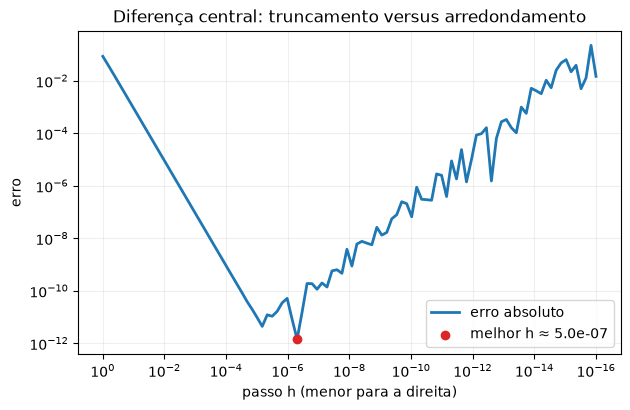

In [29]:
x0 = 1.0
hs = np.logspace(-16, 0, 100)
aprox = (np.sin(x0+hs)-np.sin(x0-hs))/(2*hs)
erro = np.abs(aprox-np.cos(x0))
h_otimo = hs[np.argmin(erro)]

fig, ax = plt.subplots(figsize=(7, 4.2))
ax.loglog(hs, erro, lw=2, label='erro absoluto')
ax.scatter([h_otimo], [erro.min()], c='#dc2626', zorder=4,
           label=f'melhor h ≈ {h_otimo:.1e}')
ax.invert_xaxis(); ax.grid(True, which='both', alpha=.2)
ax.set(xlabel='passo h (menor para a direita)', ylabel='erro',
       title='Diferença central: truncamento versus arredondamento')
ax.legend(); plt.show()


### 9.4 Aplicação eletromagnética — de cargas a potencial, campo e Poisson

Para evitar infinitos no desenho, usamos cargas suavizadas:

$$V(x,y)=\sum_i\frac{q_i}{\sqrt{(x-x_i)^2+(y-y_i)^2+\epsilon^2}},\qquad \vec E=-\nabla V.$$

As equipotenciais devem ser perpendiculares a $\vec E$. O mapa de $-\nabla^2V$ funciona como um retrato suavizado da densidade de carga, em acordo com $\nabla^2V=-\rho/\varepsilon_0$.


In [30]:
def plot_cargas(separacao=1.4, configuracao='dipolo'):
    q = np.linspace(-3, 3, 181); dx = q[1]-q[0]
    Xe, Ye = np.meshgrid(q, q); eps = .18
    cargas = [(-separacao/2,0,1), (separacao/2,0,-1)]
    if configuracao == 'iguais': cargas[1] = (separacao/2,0,1)
    Vpot = sum(qi/np.sqrt((Xe-xi)**2+(Ye-yi)**2+eps**2) for xi,yi,qi in cargas)
    dVdy, dVdx = np.gradient(Vpot, dx, dx)
    Ex, Ey = -dVdx, -dVdy
    rho_rel = -(np.gradient(dVdx, dx, axis=1)+np.gradient(dVdy, dx, axis=0))

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5), constrained_layout=True)
    levels = np.linspace(np.percentile(Vpot,3), np.percentile(Vpot,97), 22)
    ax1.contour(Xe, Ye, Vpot, levels=levels, cmap='coolwarm', linewidths=1)
    passo = 9; mag = np.hypot(Ex,Ey)
    ax1.quiver(Xe[::passo,::passo], Ye[::passo,::passo],
               Ex[::passo,::passo]/(mag[::passo,::passo]+1e-12),
               Ey[::passo,::passo]/(mag[::passo,::passo]+1e-12),
               color='0.2', alpha=.65, pivot='mid')
    for xi,yi,qi in cargas: ax1.scatter(xi,yi,s=100,c='#dc2626' if qi>0 else '#2563eb',zorder=5)
    ax1.set_title('Equipotenciais e E = -grad V')
    lim = np.percentile(np.abs(rho_rel), 99)
    im=ax2.imshow(rho_rel,extent=(-3,3,-3,3),origin='lower',cmap='RdBu_r',vmin=-lim,vmax=lim)
    ax2.set_title('-laplaciano V: densidade de carga relativa'); fig.colorbar(im,ax=ax2,shrink=.8)
    for ax in (ax1,ax2): ax.set(aspect='equal',xlim=(-3,3),ylim=(-3,3),xlabel='x',ylabel='y')
    plt.show()

interact(plot_cargas,
         separacao=FloatSlider(value=1.4,min=.5,max=3,step=.1,description='separação'),
         configuracao=['dipolo','iguais']);


interactive(children=(FloatSlider(value=1.4, description='separação', max=3.0, min=0.5), Dropdown(description=…

### 9.5 Exercícios de consolidação

Tente resolver no papel antes de abrir as respostas.

1. Para $f=x^2-y^2$, encontre as direções em que $D_{\hat u}f=0$ no ponto $(1,1)$. Relacione-as à curva de nível local.
2. Construa um campo linear 2D com divergente $6$ e rotacional $-4$. Há uma única resposta?
3. Sem calcular a integral, determine o fluxo de $\vec F=(x,y,z)$ através de uma esfera de raio $R$.
4. Um campo possui $\nabla\times\vec E=0$ numa região com um furo. Isso garante circulação zero em todo caminho fechado? Explique a hipótese topológica ausente.
5. No gráfico das cargas iguais, indique onde $\vec E=0$ e discuta se o potencial também é zero nesse ponto.

<details><summary><strong>Respostas comentadas</strong></summary>

1. $\nabla f=(2,-2)$ em $(1,1)$. As direções ortogonais, paralelas a $(1,1)$, dão derivada zero e são tangentes à hipérbole $x^2-y^2=0$.
2. Por exemplo, $\vec F=(3x+2y,3y)$: divergente $=3+3=6$ e rotacional $=0-2=-2$ — portanto ainda é preciso dobrar o termo: $\vec F=(3x+4y,3y)$ dá rotacional $-4$. Existem infinitas respostas.
3. $\nabla\cdot\vec F=3$, então $\Phi=3(4\pi R^3/3)=4\pi R^3$.
4. Não. É preciso que a região seja simplesmente conexa (e regularidade adequada). Um vórtice fora do domínio local, mas dentro do furo, é o contraexemplo clássico.
5. Por simetria, $\vec E=0$ no ponto médio. Para cargas iguais, os potenciais somam e $V>0$ ali; campo nulo não implica potencial nulo, apenas derivada espacial nula.
</details>


### Checklist de domínio

Ao terminar, você deve conseguir:

- [ ] distinguir campo escalar, campo vetorial e o tipo de saída de cada operador;
- [ ] interpretar gradiente, divergente, rotacional e Laplaciano sem depender da fórmula;
- [ ] calcular uma derivada direcional usando um versor normalizado;
- [ ] escolher entre integral direta e teorema integral;
- [ ] explicar por que $\vec E=-\nabla V$ e $\nabla^2V=-\rho/\varepsilon_0$ contam a mesma história local;
- [ ] reconhecer singularidades e hipóteses de domínio antes de aplicar identidades vetoriais.


---
## Conferência final — todos os 21 exercícios

| Exercício | Onde resolvido |
|---|---|
| E1, E2, E6, E16, E20 | Seção 1 (Gradiente) |
| E3, E17 (div) | Seção 2 (Divergente) |
| E4, E17 (rot) | Seção 3 (Rotacional) |
| E21 | Seção 4 (Laplaciano) |
| E19 | Seção 5 (Integral de linha) |
| E8 | Seção 6.1 (Teorema do Divergente) |
| E9 | Seção 6.2 (Teorema de Stokes) |
| E10, E12 | Seção 7 (Helmholtz) |
| E5, E7, E13, E14, E15, E18 | Seção 8 (Demais exercícios) |
| E11 | Conceitual — ver `01_calculo_vetorial.md`, gabarito |

Todos os resultados numéricos/simbólicos acima foram conferidos contra o gabarito analítico do capítulo — veja `01_calculo_vetorial.md`, seção "Gabarito", para as justificativas físicas completas de cada um.
